# Classical vs quantum · when does QAOA win, and how far can we simulate?

**Owner:** Tudor · **Engine:** `qgd_bench.ipynb` (every function used here is defined and explained there)

The baseline notebook solves one 5-SNP puzzle. This notebook asks what happens when puzzles grow, using a **fair race**: every method gets the same puzzles and the same budget of **B = 2048 tries**, and every shot spent on training is billed.

| Part | Question |
|---|---|
| 1 | Do we reproduce the baseline notebook exactly? |
| 2 | Why is the 5-SNP toy too easy to say anything? |
| 3 | What do bigger puzzles look like? |
| 4 | Can QAOA be trained without spending shots? |
| 5 | Who wins as puzzles grow (laptop sizes, up to 20 SNPs)? |
| 6 | How far can a classical computer simulate QAOA? |
| 7 | How hard is phasing for a classical exact solver? |
| 8 | The race beyond statevector sizes (28–100 SNPs) |
| 9 | The full run (Kaggle, 5 puzzles per size, up to 100 SNPs) |
| 10 | What we can and cannot claim |

**Scope.** Every QAOA number here is an **ideal, noiseless simulation**. Device noise and real hardware are Alex's part.

**Runtime.** About 2–3 minutes on a laptop. `BIG = True` also re-runs the full Kaggle configuration (part 9), which takes about 43 minutes on 4 CPUs.

## 0 · Setup

`%run` loads the engine. `REAL` are the "realistic read" settings used throughout: 5% of letters are read wrong and 10% are missing.

In [1]:
QGD_QUIET = True
%run qgd_bench.ipynb
import pandas as pd
import matplotlib.pyplot as plt

BIG = False          # True = rerun the full Kaggle configuration (part 9), about 43 min on 4 CPUs
SLOW_DEMOS = False   # True = also time the slow MPS setting at 20 and 24 SNPs (part 6), about 2 min
REAL = dict(error=0.05, missing=0.1)
pd.set_option("display.precision", 3)
quiet = lambda *_: None

## 1 · The toy, reproduced

Nine reads over five SNPs, copied from the baseline notebook. Each row is one read: `0`/`1` are letters, `.` means the read does not reach that SNP.

In [2]:
show_reads(TOY_READS)
A, D = pairwise_evidence(TOY_READS)
J, offset = ising(A, D)
E = diag_energies(J)                       # cost - offset for all 2^5 = 32 answers
opt = offset + E.min()
winners = ["".join(map(str, x)) for x in bits(np.flatnonzero(np.isclose(E, E.min())), 5)]
print(f"offset c0 = {offset}, best cost = {opt}, best answers = {winners}")
print(f"random guess: {len(winners)} of {2 ** 5} answers are optimal -> {len(winners) / 2 ** 5:.1%} per guess")

read  1   0 1 1 . .
read  2   1 0 0 . .
read  3   . 1 1 0 .
read  4   . 0 0 1 .
read  5   . . 1 0 1
read  6   . . 0 1 0
read  7   0 . . 0 1
read  8   1 . . 1 0
read  9   0 0 . . .
offset c0 = 12.5, best cost = 1.0, best answers = ['10010', '01101']
random guess: 2 of 32 answers are optimal -> 6.2% per guess


Same as the notebook: the best cost is **1** (one read disagrees with it, the noisy one), reached by **01101** and its mirror **10010**. A mirror is the same phasing with the two copies' names swapped, so both are correct.

Now QAOA on the toy at depths p = 1, 2, 3, next to the classical methods. Columns:
* `p_success`: chance that **one** shot (or one random guess) is optimal;
* `P_budget`: chance of seeing the optimum at least once within 2048 tries;
* `tts99`: tries needed to be 99% sure (lower is better);
* `train`, `e_pred`: how the angles were chosen, and the predicted expected cost.

In [3]:
toy = pd.DataFrame(run_bench(["toy"], 1, Config(ps=(1, 2, 3), gen=REAL), log=quiet))
toy[["method", "p_success", "P_budget", "tts99", "train", "e_pred"]]

,method,p_success,P_budget,tts99,train,e_pred
0,brute,1.000,1.0,32.000,NaN,NaN
1,random,0.062,1.0,71.355,NaN,NaN
2,local,1.000,1.0,13.288,NaN,NaN
3,sa,1.000,1.0,39.000,NaN,NaN
4,qaoa-p1,0.527,1.0,6.157,closed-form,5.833
5,qaoa-p2,0.757,1.0,3.252,transfer,NaN
6,qaoa-p3,0.706,1.0,3.757,transfer,NaN


**What we see**
* The notebook's COBYLA reaches an expected cost of **7.798**. Our p = 1 formula reaches **5.833** with **0 shots** (lower is better; check 9.4 in the engine).
* Deeper circuits put more probability on the two optimal answers: 53% of the shots at p = 1, about 70–76% at p = 2 and 3. So 4–6 shots already give 99% confidence.
* Every method finds the optimum within 2048 tries, including random guessing. That is the problem with the toy (part 2).

## 2 · Why the toy is too easy

Random guessing finds an optimum with chance (number of optimal answers) / $2^N$ per guess. With the usual 2 optima (an answer and its mirror):

In [4]:
ns = [5, 8, 12, 16, 20, 26, 32, 64, 100]
pd.DataFrame({"N SNPs": ns, "answers 2^N": [f"{2.0 ** n:.3g}" for n in ns],
              "one guess": [f"{2 / 2 ** n:.2e}" for n in ns],
              "2048 guesses": [f"{1 - (1 - 2 / 2 ** n) ** 2048:.1%}" for n in ns]})

,N SNPs,answers 2^N,one guess,2048 guesses
0,5,32,6.25e-02,100.0%
1,8,256,7.81e-03,100.0%
2,12,4.1e+03,4.88e-04,63.2%
3,16,6.55e+04,3.05e-05,6.1%
4,20,1.05e+06,1.91e-06,0.4%
5,26,6.71e+07,2.98e-08,0.0%
6,32,4.29e+09,4.66e-10,0.0%
7,64,1.84e+19,1.08e-19,0.0%
8,100,1.27e+30,1.58e-30,0.0%


At 5 SNPs, 2048 random guesses are almost certain to hit; at 20 SNPs they almost never do. Larger puzzles separate methods that all succeed on the toy at this budget, which is why the race uses a puzzle generator.

## 3 · Bigger puzzles: the generator

`make_instance(n, ...)` hides a random answer (`truth`), then simulates sequencing:

| Knob | Default | Meaning |
|---|---|---|
| `coverage` | 6 | each SNP is covered by about 6 reads |
| `read_len` | 2–4 | each read covers 2 to 4 neighbouring SNPs (short reads) |
| `error` | 0 (`REAL`: 0.05) | chance that a letter is read wrong |
| `missing` | 0 (`REAL`: 0.1) | chance that a letter is missing from a read |
| `gaps` | 0 | places no read crosses (the two sides cannot be phased together) |

The truth is used **only for grading** (switch errors); no solver sees it.

In [5]:
demo = make_instance(12, seed=0, **REAL)
show_reads(demo.reads, demo.truth)
Jd, offd = ising(*pairwise_evidence(demo.reads))
print(f"{len(demo.reads)} reads, {np.count_nonzero(Jd)} linked pairs, band width {bandwidth(Jd)}, "
      f"truth cost {costs(demo.truth[None], Jd, offd)[0]:g}, best cost {banded_exact(Jd, offd):g}")

read  1   . . . . . . . 1 . . . .
read  2   . . . . . . . 0 0 1 . .
read  3   . . . . . . 0 0 . . . .
read  4   . . . . . . 0 0 0 1 . .
read  5   . . . . . 0 0 . 0 . . .
read  6   . . . . . . . 0 0 1 . .
read  7   . . 1 0 0 0 . . . . . .
read  8   . . . . 0 0 . . . . . .
read  9   . . . . . 0 0 . . . . .
read 10   . . . . . . 0 0 0 1 . .
read 11   . . . . . . . . 0 0 0 0
read 12   . . . . . 0 0 . . . . .
read 13   . . . . . 1 . . . . . .
read 14   . . . . . . . . 1 . . .
read 15   . . . 0 0 0 . . . . . .
read 16   . 1 1 . . . . . . . . .
read 17   . . 1 0 0 . . . . . . .
read 18   . . . . . . . . . . 1 .
read 19   . . . 0 1 1 1 . . . . .
read 20   . . . . . . . . . 1 1 .
read 21   . . . . . . 0 0 0 1 . .
read 22   . . . . . . . . . 0 0 .
read 23   . . . . . . . . 0 1 1 .
read 24   . . . . . . 1 1 . . . .
read 25   1 1 . . . . . . . . . .
truth     1 1 1 0 0 0 0 0 0 1 1 1   <- copy A (copy B is its mirror)
25 reads, 22 linked pairs, band width 3, truth cost 6, best cost 6


**Band width 3:** a read covers at most 4 neighbouring SNPs, so only SNPs at most 3 apart are linked. This matters twice later: it keeps the MPS simulator fast (part 6) and makes the problem easy for a classical exact solver (part 7).

With read errors, the hidden truth is not always the cheapest answer. The race measures "did you find the cheapest answer" (`P_budget`, `tts99`) and "how close to the truth" (`switch_err`) separately.

## 4 · Training QAOA without spending shots

The baseline notebook trains with COBYLA on **exact statevector probabilities**, so it also uses zero training shots. Our change is to avoid repeated statevector simulation for p = 1, and to reuse small-puzzle training for p = 2, 3. This saves classical simulation work, not shots relative to that baseline. A shot-based trainer would need its shots billed separately.

### 4.1 p = 1: a formula

For p = 1 the expected cost E(γ, β) has an exact formula (engine 6.3), so we can draw the whole landscape and pick the best point without running a circuit. The map below is the toy's landscape; darker = lower expected cost.

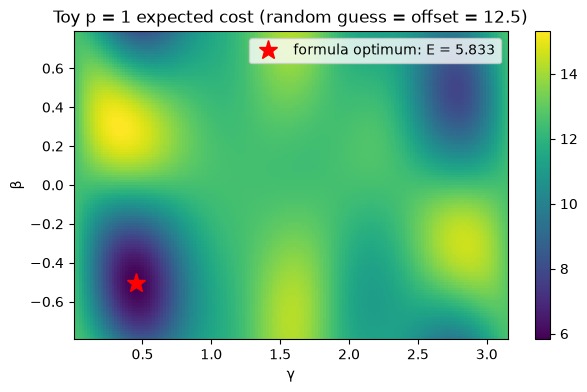

In [6]:
gs = np.linspace(0.01, np.pi, 160)
bs = np.linspace(-np.pi / 4, np.pi / 4, 120)
land = np.array([p1_energy(J, offset, gs, b) for b in bs])
(g1, b1), e1, _ = train_p1(J, offset)
fig, ax = plt.subplots(figsize=(7, 4))
im = ax.pcolormesh(gs, bs, land, cmap="viridis", shading="auto")
ax.plot(g1, b1, "r*", ms=14, label=f"formula optimum: E = {e1:.3f}")
ax.set(xlabel="γ", ylabel="β", title=f"Toy p = 1 expected cost (random guess = offset = {offset:g})")
fig.colorbar(im, ax=ax)
ax.legend(loc="upper right")
plt.show()

### 4.2 p = 2, 3: train once on small puzzles, reuse everywhere

`train_transfer(p)` tunes angles on 9 small puzzles (8–12 SNPs) with the exact simulator and keeps the median. Those angles then run unchanged on every puzzle up to 100 SNPs. The training is classical and uses no shots.

In [7]:
t = time.time()
transfer = {p: train_transfer(p, gen=REAL)[0] for p in (2, 3)}
print(f"trained in {time.time() - t:.1f} s")
kaggle = {2: [0.4638, 0.6379, -0.5934, -0.3042], 3: [0.3872, 0.5905, 0.6692, -0.6394, -0.4468, -0.2430]}
pd.DataFrame([dict(p=p, angles=np.round(a, 4), **{"same as the Kaggle run": np.allclose(a, kaggle[p], atol=1e-3)})
              for p, a in transfer.items()])

trained in 7.1 s


,p,angles,same as the Kaggle run
0,2,"[0.4637, 0.6379, -0.5934, -0.3041]",True
1,3,"[0.3871, 0.5901, 0.669, -0.6396, -0.4467, -0.243]",True


Angles are listed as `[γ1 … γp, β1 … βp]`. The γ's grow and the |β|'s shrink layer by layer: a smooth "annealing-like" schedule, as expected for good QAOA angles.

### 4.3 Do reused angles lose much? (concentration)

On 4 unseen 14-SNP puzzles we compare the transferred angles with angles tuned on that exact puzzle (COBYLA on the exact expected cost). The quality is the expected-cost version of `score`: 1 = always the optimum, 0 = no better than a random guess.

In [8]:
from scipy.optimize import minimize

rows = []
for k in range(4):
    inst = make_instance(14, seed=500 + k, **REAL)
    Jk, offk = ising(*pairwise_evidence(inst.reads))
    Ek = diag_energies(Jk)
    gap = -Ek.min()
    quality = lambda e: (offk - e) / gap
    f = lambda x: float(np.abs(qaoa_state(Jk, x, Ek)) ** 2 @ Ek) + offk
    rows.append(dict(puzzle=k, p=1, transferred=np.nan, tuned=quality(train_p1(Jk, offk)[1])))
    for p in (2, 3):
        tuned = minimize(f, transfer[p], method="COBYLA", options={"maxiter": 400}).fun
        rows.append(dict(puzzle=k, p=p, transferred=quality(f(transfer[p])), tuned=quality(tuned)))
conc = pd.DataFrame(rows)
conc.groupby("p")[["transferred", "tuned"]].mean()

,transferred,tuned
p,,
1,NaN,0.500
2,0.637,0.664
3,0.703,0.738


On these four held-out puzzles, transferred angles keep about 95% of the quality of per-puzzle tuning. Both approaches use zero shots here, but transfer avoids repeating the classical optimizer on each new puzzle. (p = 1 has no transferred column: its formula is cheap enough to run on every puzzle.)

## 5 · The race on a laptop: up to 20 SNPs

3 puzzles per size, realistic reads, QAOA at p = 1, 2, 3, budget B = 2048. QAOA runs on the exact numpy simulator, so its success chance per shot is exact.

The contestants (engine part 5): `brute` enumerates all $2^N$ answers (the referee), `random` guesses, `local` = greedy start + one-flip descent, `sa` = simulated annealing.

In [9]:
race = pd.DataFrame(run_bench(["toy", 8, 12, 16, 20], 3, Config(ps=(1, 2, 3), gen=REAL)))
race.groupby(["n", "method"])["P_budget"].median().unstack().round(3)

pre-trained p=2 angles on small instances (3144 classical evaluations): [ 0.4637  0.6379 -0.5934 -0.3041]


pre-trained p=3 angles on small instances (4331 classical evaluations): [ 0.3871  0.5901  0.669  -0.6396 -0.4467 -0.243 ]
N=toy: 7.9s  P(optimum within budget): brute=1.00, random=1.00, local=1.00, sa=1.00, qaoa-p1=1.00, qaoa-p2=1.00, qaoa-p3=1.00


N=8: 0.7s  P(optimum within budget): brute=1.00, random=1.00, local=1.00, sa=1.00, qaoa-p1=1.00, qaoa-p2=1.00, qaoa-p3=1.00


N=12: 0.8s  P(optimum within budget): brute=1.00, random=0.63, local=1.00, sa=0.99, qaoa-p1=1.00, qaoa-p2=1.00, qaoa-p3=1.00


N=16: 0.9s  P(optimum within budget): brute=1.00, random=0.06, local=1.00, sa=0.70, qaoa-p1=1.00, qaoa-p2=1.00, qaoa-p3=1.00


N=20: 11.4s  P(optimum within budget): brute=1.00, random=0.00, local=0.98, sa=0.46, qaoa-p1=0.99, qaoa-p2=1.00, qaoa-p3=1.00


method,brute,local,qaoa-p1,qaoa-p2,qaoa-p3,random,sa
n,,,,,,,
5,1.0,1.000,1.000,1.0,1.0,1.000,1.000
8,1.0,1.000,1.000,1.0,1.0,1.000,1.000
12,1.0,1.000,1.000,1.0,1.0,0.632,1.000
16,1.0,1.000,1.000,1.0,1.0,0.061,0.719
20,1.0,0.984,0.999,1.0,1.0,0.004,0.453


**`P_budget`** (median over the puzzles): the chance of finding the optimum within 2048 tries. Random guessing collapses after 12 SNPs. Simulated annealing degrades. Local search and QAOA stay near 1.

**`tts99`**: tries needed to be 99% sure. This separates the methods that all reach P ≈ 1:

In [10]:
race.groupby(["n", "method"])["tts99"].median().unstack().round(0)

method,brute,local,qaoa-p1,qaoa-p2,qaoa-p3,random,sa
n,,,,,,,
5,3.200e+01,13.0,6.0,3.0,4.0,7.100e+01,39.0
8,2.560e+02,80.0,34.0,20.0,15.0,5.870e+02,206.0
12,4.096e+03,201.0,109.0,52.0,21.0,9.429e+03,504.0
16,6.554e+04,602.0,275.0,82.0,41.0,1.509e+05,2283.0
20,1.049e+06,1541.0,1385.0,379.0,218.0,2.414e+06,5156.0


**Reading it.** From 8 SNPs on, QAOA p = 3 needs the fewest tries (on the toy, p = 2 edges it). Brute force doubles with every SNP. Careful: one QAOA try is one **shot**, and one local-search try is one **cost evaluation**. They are counted the same way, but they cost different things in time and money (part 10).

All five panels at once (median per size):

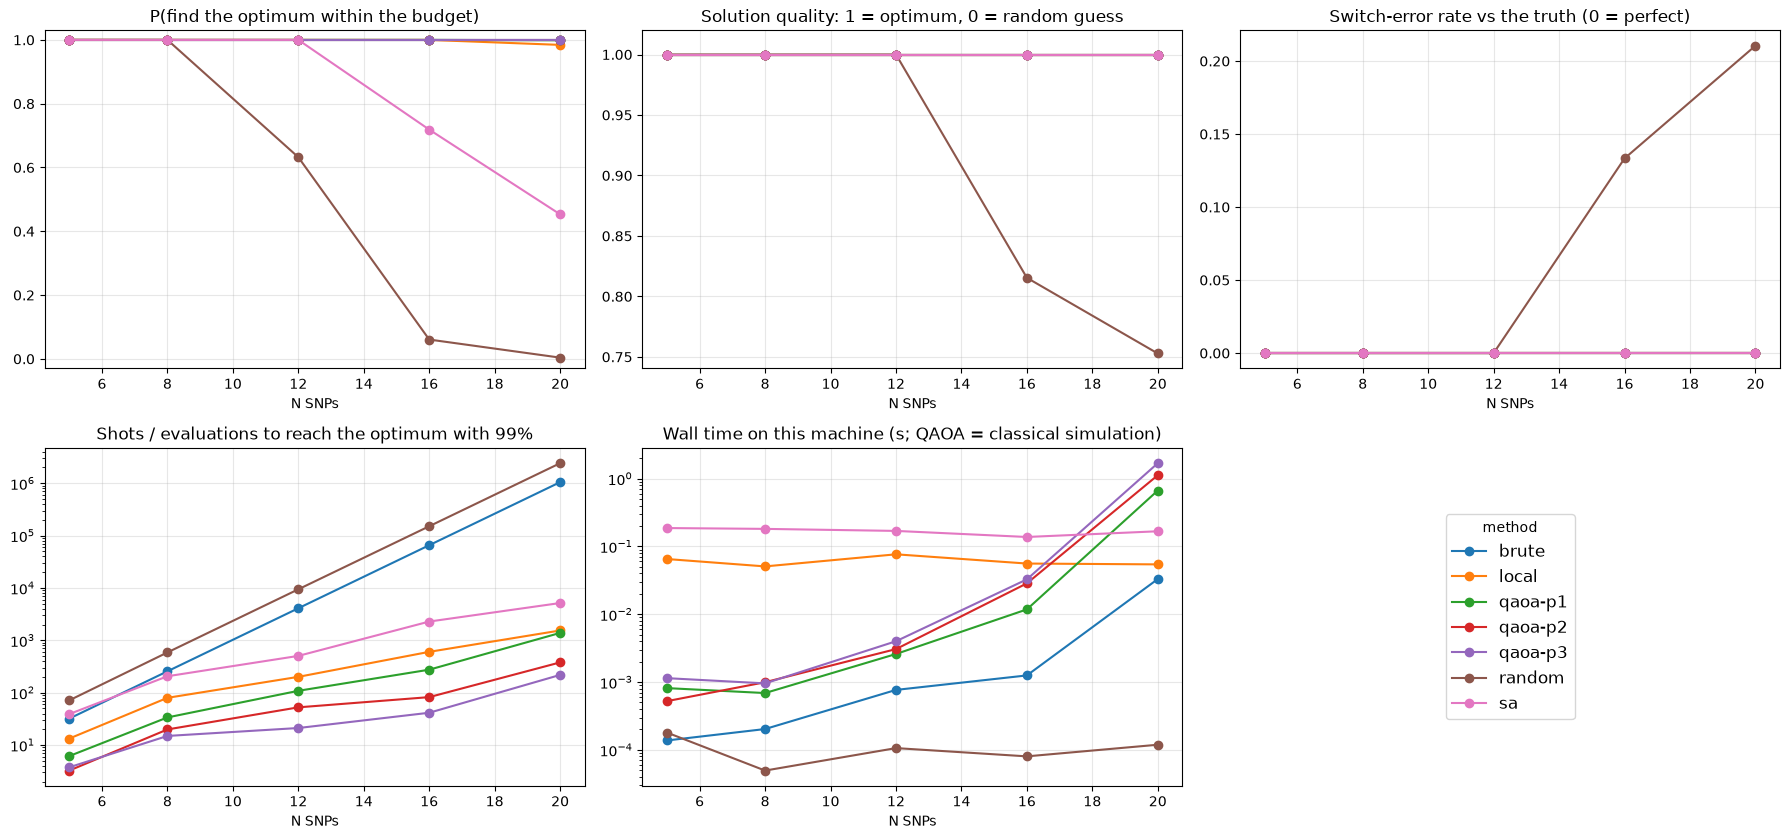

In [11]:
plot(race)

* **Top row:** `P_budget` (higher is better); `score`, the quality of the best answer found (1 = optimum, 0 = random guess); switch-error rate against the hidden truth (0 = perfect).
* **Bottom row:** `tts99` (log scale, lower is better); wall time **of the simulation on this machine**. The QAOA time is the cost of simulating it classically, not of running it on a quantum computer.

## 6 · How far can a classical computer simulate QAOA?

### 6.1 Statevector: memory doubles with every qubit

An exact simulator stores $2^N$ complex amplitudes of 16 bytes each.

In [12]:
mem = pd.DataFrame({"N qubits": [20, 24, 26, 30, 34, 40, 50, 100]})
mem["statevector memory"] = [f"{16 * 2 ** n / 1e9:,.3g} GB" for n in mem["N qubits"]]
mem["fits in"] = ["laptop", "laptop", "laptop (1 GB, our limit)", "big server", "supercomputer node", "no", "no", "no"]
mem

,N qubits,statevector memory,fits in
0,20,0.0168 GB,laptop
1,24,0.268 GB,laptop
2,26,1.07 GB,"laptop (1 GB, our limit)"
3,30,17.2 GB,big server
4,34,275 GB,supercomputer node
5,40,1.76e+04 GB,no
6,50,1.8e+07 GB,no
7,100,2.03e+22 GB,no


### 6.2 Matrix product states (MPS): memory follows entanglement, not $2^N$

Our couplings only link SNPs at most 3 apart (band 3), so entanglement stays local and Aer's MPS simulator handles 100 qubits. One Aer setting matters a lot: an `RZZ` between non-neighbouring qubits makes Aer swap qubits, and the swap direction changes the cost dramatically. The engine uses `mps_swap_right`.

Below: time for one p = 1 circuit with 2048 shots.

In [13]:
def time_mps(n, p=1, direction="mps_swap_right"):
    inst = make_instance(n, seed=0, **REAL)
    Jn, _ = ising(*pairwise_evidence(inst.reads))
    qc, theta, _ = make_qaoa(Jn, p)
    angles = np.r_[[0.5] * p, [-0.3] * p]
    job = dict(J=Jn, E=None, builder="baseline", angles=angles, circuit=qc.assign_parameters(dict(zip(theta, angles))))
    AER_OPTIONS["matrix_product_state"]["mps_swap_direction"] = direction
    try:
        t = time.time()
        REGISTRY["backend"]["aer_mps"](job, 2048, 1)
        return time.time() - t
    finally:
        AER_OPTIONS["matrix_product_state"]["mps_swap_direction"] = "mps_swap_right"


time_mps(8)   # warm-up: the first Aer call loads the library
sizes = [16, 18] + ([20, 24] if SLOW_DEMOS else [])
swap = pd.DataFrame([dict(N=n, swap_right_s=time_mps(n), swap_left_s=time_mps(n, direction="mps_swap_left")) for n in sizes])
swap["slower by"] = (swap.swap_left_s / swap.swap_right_s).round(0)
swap

,N,swap_right_s,swap_left_s,slower by
0,16,0.224,1.577,7.0
1,18,0.200,2.584,13.0


The default (`mps_swap_left`) slows down fast as N grows: we measured about 2 s at 16–18 SNPs, 23 s at 20 and **99 s at 24**, against 0.1–0.3 s with `mps_swap_right` (set `SLOW_DEMOS = True` to see 20 and 24). With the right setting, time grows slowly with size:

In [14]:
pd.DataFrame([dict(N=n, p=p, seconds=round(time_mps(n, p), 2)) for n in (24, 48, 100) for p in (1, 3)])

,N,p,seconds
0,24,1,0.25
1,24,3,1.10
2,48,1,0.38
3,48,3,2.21
4,100,1,0.62
5,100,3,5.54


## 7 · How hard is phasing for a classical exact solver?

Because reads are short (band 3), the exact optimum can be found by dynamic programming over a window of the last 3 SNPs (engine 4.2): $N \times 2^3$ steps, **linear in N**.

In [15]:
dp = []
for n in (100, 300, 1000, 2000):
    inst = make_instance(n, seed=1, **REAL)
    Jn, offn = ising(*pairwise_evidence(inst.reads))
    t = time.time()
    best = banded_exact(Jn, offn)
    dp.append(dict(N=n, band=bandwidth(Jn), exact_best=best, seconds=round(time.time() - t, 4), answers=f"2^{n}"))
pd.DataFrame(dp)

,N,band,exact_best,seconds,answers
0,100,3,55.0,0.004,2^100
1,300,3,164.0,0.010,2^300
2,1000,3,459.0,0.039,2^1000
3,2000,3,984.0,0.147,2^2000


Exact answers for 2000 SNPs in a fraction of a second. **Short-read phasing is not where a quantum computer is needed.** The DP cost grows like $2^{\text{band}}$, so it only struggles when links are long-range (long reads, Hi-C contacts): that is where a quantum method could matter.

The race uses this DP as the referee above 24 SNPs, so `P_budget` is still measured against the true optimum at 100 SNPs.

## 8 · The race beyond statevector sizes: 28–100 SNPs

QAOA now runs on Aer MPS (sampled, 2048 shots), with the same zero-shot angles. Brute force is out; the band DP is the referee. 2 puzzles per size here (5 in the Kaggle run).

In [16]:
big = pd.DataFrame(run_bench([28, 32, 48, 64, 100], 2, Config(methods=("random", "local", "sa", "qaoa"), ps=(1, 2, 3), gen=REAL)))
pd.concat({"P_budget": big.groupby(["n", "method"])["P_budget"].median().unstack().round(2),
           "switch_err": big.groupby(["n", "method"])["switch_err"].median().unstack()}, axis=1)

pre-trained p=2 angles on small instances (3144 classical evaluations): [ 0.4637  0.6379 -0.5934 -0.3041]


pre-trained p=3 angles on small instances (4331 classical evaluations): [ 0.3871  0.5901  0.669  -0.6396 -0.4467 -0.243 ]


N=28: 12.7s  P(optimum within budget): random=0.00, local=0.84, sa=0.38, qaoa-p1=0.00, qaoa-p2=0.92, qaoa-p3=1.00


N=32: 5.5s  P(optimum within budget): random=0.00, local=0.52, sa=0.16, qaoa-p1=0.43, qaoa-p2=0.75, qaoa-p3=0.82


N=48: 8.3s  P(optimum within budget): random=0.00, local=0.12, sa=0.05, qaoa-p1=0.00, qaoa-p2=0.00, qaoa-p3=0.00


N=64: 8.1s  P(optimum within budget): random=0.00, local=0.02, sa=0.01, qaoa-p1=0.00, qaoa-p2=0.00, qaoa-p3=0.00


N=100: 13.0s  P(optimum within budget): random=0.00, local=0.00, sa=0.00, qaoa-p1=0.00, qaoa-p2=0.00, qaoa-p3=0.00


P_budget                                      switch_err          \
method    local qaoa-p1 qaoa-p2 qaoa-p3 random    sa      local qaoa-p1   
n                                                                         
28         0.84    0.00    0.92    1.00    0.0  0.38        0.0     2.5   
32         0.52    0.43    0.75    0.82    0.0  0.16        0.5     1.0   
48         0.12    0.00    0.00    0.00    0.0  0.05        0.0     6.5   
64         0.02    0.00    0.00    0.00    0.0  0.01        1.0     8.5   
100        0.00    0.00    0.00    0.00    0.0  0.00        4.5    19.0   

                                    
method qaoa-p2 qaoa-p3 random   sa  
n                                   
28         0.0     0.5    5.5  0.0  
32         0.5     0.5    6.5  0.0  
48         3.5     2.5   12.0  0.5  
64         5.0     5.5   19.0  1.5  
100       16.0    13.5   32.5  4.0

**What we see**
* At 28–32 SNPs QAOA p = 3 still finds the optimum, more reliably than local search.
* Success falls sharply at 48+ SNPs. Some puzzles and classical chains still succeed; in the full Kaggle run even QAOA p = 3 finds an optimum on one 48-SNP puzzle. A zero measured rate means **none observed in that sample**, not that success is impossible.
* `switch_err` shows the answers are still close to the truth: a few switches out of dozens of SNPs. Annealing is closest at 100 SNPs.

## 9 · The full run (Kaggle: 5 puzzles per size, 4 CPUs, about 43 minutes)

Same engine and seeds as above, more puzzles. Medians over the 5 puzzles, realistic reads, selected sizes. N = 5 is the notebook's toy; up to 26 SNPs QAOA is exact numpy, from 28 Aer MPS.

**`P_budget`: chance of finding the optimum within 2048 tries**

| N | random | sa | local | QAOA p=1 | QAOA p=2 | QAOA p=3 |
|---|---|---|---|---|---|---|
| 5 (toy) | 1.00 | 1.00 | 1.00 | 1.00 | 1.00 | 1.00 |
| 12 | 0.63 | 1.00 | 1.00 | 1.00 | 1.00 | 1.00 |
| 16 | 0.06 | 0.72 | 1.00 | 1.00 | 1.00 | 1.00 |
| 20 | 0.00 | 0.50 | 0.98 | 1.00 | 1.00 | 1.00 |
| 24 | 0.00 | 0.31 | 0.94 | 0.94 | 1.00 | 1.00 |
| 26 | 0.00 | 0.31 | 0.89 | 0.65 | 0.99 | **1.00** |
| 28 | 0.00 | 0.31 | 0.80 | 0.00 | 0.95 | **1.00** |
| 32 | 0.00 | 0.19 | 0.55 | 0.00 | 0.87 | **1.00** |
| 48 | 0.00 | 0.06 | **0.09** | 0.00 | 0.00 | 0.00 |
| 64 | 0.00 | 0.00 | **0.02** | 0.00 | 0.00 | 0.00 |
| 100 | 0.00 | 0.00 | 0.00 | 0.00 | 0.00 | 0.00 |

**`tts99`: estimated tries to be 99% sure of the optimum** (∞ = zero estimated success; not proof of impossibility)

| N | sa | local | QAOA p=1 | QAOA p=2 | QAOA p=3 | local ÷ p=3 |
|---|---|---|---|---|---|---|
| 12 | 550 | 201 | 109 | 52 | **21** | 9.5× |
| 16 | 2,283 | 556 | 461 | 110 | **44** | 12.5× |
| 20 | 4,804 | 1,380 | 1,385 | 367 | **165** | 8.3× |
| 24 | 8,159 | 1,758 | 3,309 | 575 | **239** | 7.4× |
| 26 | 9,156 | 2,433 | 8,986 | 1,944 | **699** | 3.5× |
| 28 | 10,570 | 4,254 | ∞ | 3,141 | **1,345** | 3.2× |
| 32 | 20,170 | 6,139 | ∞ | 4,713 | **1,570** | 3.9× |
| 48 | 63,578 | **41,775** | ∞ | ∞ | ∞ | – |
| 64 | ∞ | **486,591** | ∞ | ∞ | ∞ | – |

**Median switch errors at 100 SNPs:** sa 4, local 7, QAOA p=3 9, p=2 13, p=1 19, random 35.

**Error-free reads** (a third run, 8–24 SNPs) tell the same story: QAOA p = 3 has the lowest `tts99` at every size (e.g. 510 vs local 1,655 at 24 SNPs).

With `BIG = True` the cell below reruns all three configurations and saves `results/<run>/results.csv` and `scaling.png`.

In [17]:
KAGGLE_RUNS = {
    "sv_realistic": (["toy", 8, 12, 16, 20, 22, 24, 26], Config(ps=(1, 2, 3), gen=REAL)),
    "mps_realistic": ([28, 32, 48, 64, 100], Config(methods=("random", "local", "sa", "qaoa"), ps=(1, 2, 3), gen=REAL)),
    "sv_noiseless": ([8, 12, 16, 20, 24], Config(ps=(1, 2, 3))),
}
if BIG:
    for name, (sizes, cfg) in KAGGLE_RUNS.items():
        t = time.time()
        df = pd.DataFrame(run_bench(sizes, 5, cfg))
        out = os.path.join("results", name)
        os.makedirs(out, exist_ok=True)
        df.to_csv(os.path.join(out, "results.csv"), index=False)
        plot(df, out)
        print(f"{name}: {len(df)} rows in {time.time() - t:.0f} s -> {out}")
        display(summarize(df))
else:
    print("BIG = False: showing the stored Kaggle medians above. Set BIG = True to rerun them.")

BIG = False: showing the stored Kaggle medians above. Set BIG = True to rerun them.


## 10 · What we can claim, and what we cannot

**We can claim (ideal simulation, short-read puzzles):**
* The baseline circuit can be trained with **zero shots**: an analytic expected-cost formula plus a one-dimensional search for p = 1, and angles transferred from small puzzles for p = 2, 3. Transfer retains about 95% of tuned quality on the four held-out puzzles in 4.3.
* Counting one shot as one try, **QAOA p = 3 has the lowest median TTS99 among the budgeted methods tested at 8–32 SNPs**: 3.9× fewer tries than local search at 32 SNPs. Training shots are included (zero here), but classical pre-training time is a separate cost.
* Aer MPS with `mps_swap_right` simulates these circuits at 100 qubits in seconds.

**We cannot claim:**
* **A speed-up in time.** A shot on hardware and a cost evaluation on a CPU have very different prices, and the CPU methods take milliseconds.
* **That the problem needs a quantum computer.** The band DP solves 2000 short-read SNPs exactly in under a second (part 7).
* **Reliable success at 48+ SNPs.** QAOA has zero observed successes on the median Kaggle puzzle at those sizes; local-search success rates also become small. This is not a claim that every run fails (part 8).
* **Hardware performance.** Everything is noiseless simulation. The effects of device noise and routing have not been measured here.
* **State of the art.** `local` and `sa` are simple reference methods, not tools such as WhatsHap or HapCUT2.

**Where a quantum method could matter:** long-range links (long reads, Hi-C) widen the band, and the DP's cost grows like $2^{\text{band}}$. Those puzzles would need a different generator, and they are the next experiment.